![Banner](../images/09_13_banner_rs_soil_moisture.png)

# ASCAT and the TU Wien Change Detection Approach

The Advanced Scatterometer (ASCAT) on the MetOp satellites was built to measure winds over the
ocean, but over land its C-band backscatter responds to soil moisture. TU Wien turned that response
into a global soil moisture product without any radiative transfer model: for every location, the
driest and wettest backscatter of a long record define 0 and 100 %, and each new measurement is
placed between them. The result is a degree of saturation, not a volumetric water content. This
notebook uses the ESA CCI ACTIVE record, which is built from ASCAT (and the earlier ERS
scatterometers) with this method, to explain change detection, convert degree of saturation to
volumetric soil moisture with SoilGrids porosity, compare it with SMAP and a station, and compute
the Soil Water Index.

## Overview

### Scatterometers

ASCAT (MetOp-A 2006, MetOp-B 2012, MetOp-C 2018) is a real-aperture radar at 5.255 GHz, VV
polarized, with three antennas on each side looking at three azimuths. Each location is seen at
several incidence angles (25 to 65 degrees) about once a day per satellite, with a footprint of
25 to 50 km resampled to 12.5 km.

### The TU Wien change detection method

Backscatter depends on soil moisture, vegetation and roughness. Over a long record at one location
roughness changes little, and vegetation mostly changes the dependence of backscatter on incidence
angle. Wagner et al. (1999) therefore:

1. normalize every measurement to a reference angle (40 degrees) with a seasonally varying slope
   (the slope carries the vegetation signal);
2. take the lowest and highest normalized backscatter of the record as the dry and wet references;
3. express each measurement as surface soil moisture in degree of saturation
   `ms = (sigma40 - sigma_dry) / (sigma_wet - sigma_dry)`, 0 to 100 %.

The approach needs no soil or vegetation ancillary data and is robust, but its output is relative:
the same 50 % means more water in a clay than in a sand. Volumetric water content follows with
porosity: `theta = ms phi`.

### The Soil Water Index

Wagner et al. (1999) also proposed estimating the moisture of deeper layers from the surface
series with an exponential filter, `SWI(t) = sum ms(ti) exp(-(t - ti)/T) / sum exp(-(t - ti)/T)`, with a
characteristic time `T` of days to weeks. Notebook 24 uses the same filter for root-zone estimation.

### ESA CCI ACTIVE

The ESA Climate Change Initiative merges active (scatterometer) and passive (radiometer) records.
Its ACTIVE product is the scatterometer record produced with TU Wien's method: ERS-1 and ERS-2 from
1991 and ASCAT from 2007, rescaled to one another, in degree of saturation (%) on a 0.25 degree grid.
It is served openly by CEDA, so it is used here instead of the H SAF ASCAT products, which need a
registration.

## Scatterometer Soil Moisture with GeoLattice

| Function | Purpose |
|---|---|
| `sm.read_ascat(bbox, dates=...)` or `sd.cci("ACTIVE")` | ESA CCI ACTIVE (ASCAT) degree of saturation, % |
| `sm.load_soilgrids`, `sm.porosity_from_texture` | porosity from texture |
| `sm.saturation_to_volumetric` | degree of saturation to m3 m-3 |
| `sm.exponential_filter` | Soil Water Index |
| `sm.regrid`, `sm.validation_metrics` | regridding and comparison with SMAP and in situ data |

### Learning objectives

1. Explain how change detection turns backscatter into a degree of saturation.
2. Read the scatterometer record and look at its dry and wet extremes.
3. Convert degree of saturation to volumetric soil moisture with SoilGrids porosity.
4. Compare the converted record with SMAP and with a station.
5. Compute the Soil Water Index and choose its characteristic time against deeper sensors.

### Data

| Dataset | Content |
|---|---|
| ESA CCI SM v09.2 ACTIVE, 2015 to 2024 | ASCAT degree of saturation (%), 0.25 degree, Iowa region |
| SoilGrids 2.0, 0 to 5 cm, about 4 km | sand, clay, organic carbon, bulk density |
| SMAP L3 Enhanced | 9 km retrievals, aggregated to 0.25 degree |
| USCRN Des Moines 17 E | in situ soil moisture at 5 to 100 cm |

### Contents

- Setup
- The scatterometer record
- Dry and wet references
- Porosity from SoilGrids
- From degree of saturation to volumetric soil moisture
- Comparison with SMAP and the station
- The Soil Water Index
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

act = sd.cci("ACTIVE")  # ESA CCI ACTIVE (ASCAT) 2015 to 2024, degree of saturation in %
st = sd.STATIONS.loc["USCRN Des Moines 17 E"]  # in situ station
u = sd.uscrn().resample("1D").mean()  # daily in situ means
print(act.sizes, "| units:", act.attrs.get("units"))  # dimensions

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


Frozen({'time': 3653, 'lat': 18, 'lon': 30}) | units: %


## The scatterometer record

cells with a value on an average day: 61%; by season:
{1: 4.0, 2: 14.0, 3: 51.0, 4: 69.0, 5: 83.0, 6: 91.0, 7: 97.0, 8: 95.0, 9: 95.0, 10: 79.0, 11: 36.0, 12: 14.0}


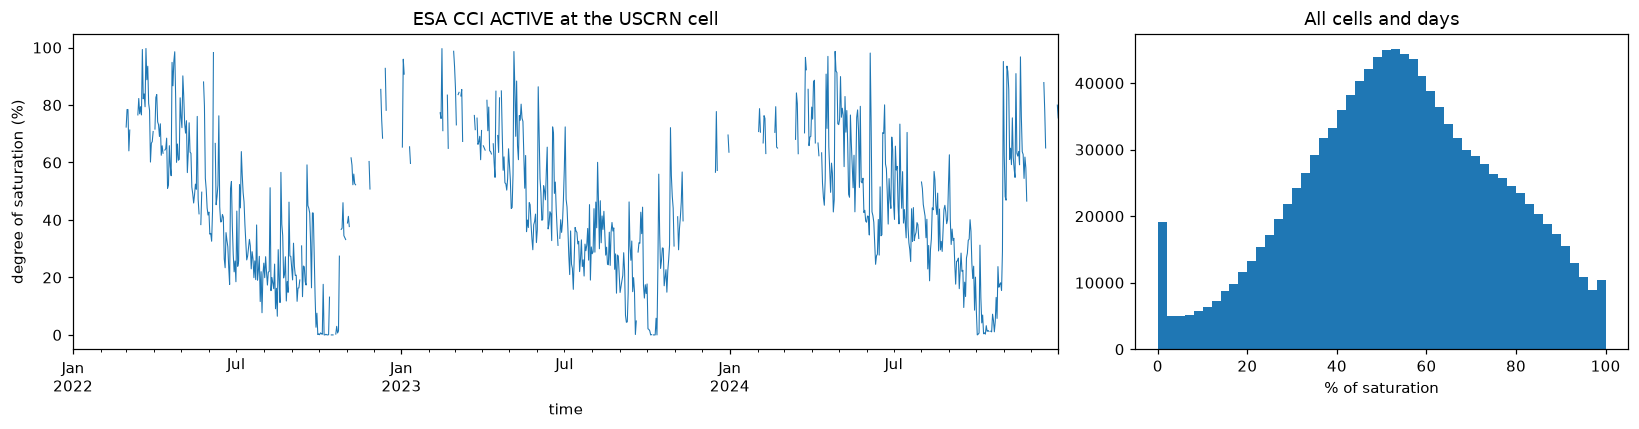

In [2]:
ms = sm.mask_quality(act, level="all").sm  # drop frozen and water flags, keep other retrievals
cover = ms.notnull().mean(("lat", "lon")).to_series()  # share of cells per day
print(f"cells with a value on an average day: {cover.mean():.0%}; by season:")  # coverage
print((cover.groupby(cover.index.month).mean() * 100).round(0).to_dict())  # by month
pt = ms.sel(lat=st.lat, lon=st.lon, method="nearest").to_series()  # cell of the station
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})  # series and histogram
pt.loc["2022":"2024"].plot(ax=ax[0], lw=0.7); ax[0].set_ylabel("degree of saturation (%)"); ax[0].set_title("ESA CCI ACTIVE at the USCRN cell")  # series
ms.plot.hist(ax=ax[1], bins=50); ax[1].set_xlabel("% of saturation"); ax[1].set_title("All cells and days")  # distribution
plt.tight_layout(); plt.show()  # draw

The record is nearly complete from June to September (more than 90 % of cells every day) and almost
empty in winter, when frozen soil and snow are flagged (4 % in January).

## Dry and wet references

By construction the record spans the range between the driest and wettest conditions of each cell.
The 2nd and 98th percentiles of the cell series show how the references are reached.

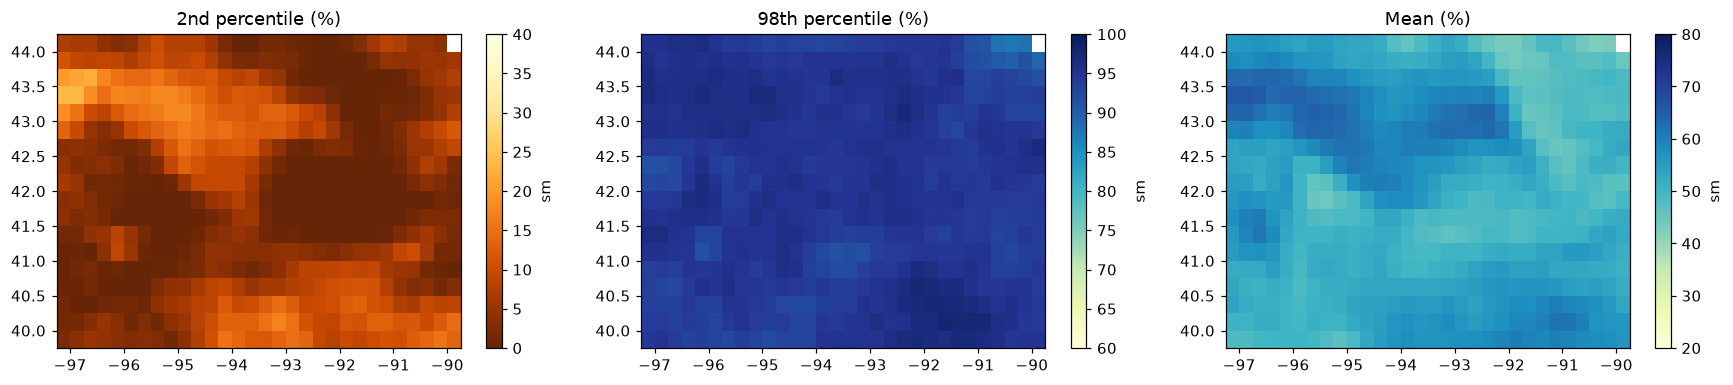

median 2nd percentile 4 %, 98th 95 %


In [3]:
lo = ms.quantile(0.02, "time"); hi = ms.quantile(0.98, "time")  # near-dry and near-wet references
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))  # three maps
lo.plot(ax=ax[0], cmap="YlOrBr_r", vmin=0, vmax=40); ax[0].set_title("2nd percentile (%)")  # dry
hi.plot(ax=ax[1], cmap="YlGnBu", vmin=60, vmax=100); ax[1].set_title("98th percentile (%)")  # wet
ms.mean("time").plot(ax=ax[2], cmap="YlGnBu", vmin=20, vmax=80); ax[2].set_title("Mean (%)")  # mean
for a in ax: a.set_xlabel(""); a.set_ylabel("")  # clean axes
plt.tight_layout(); plt.show()  # draw
print(f"median 2nd percentile {float(lo.median()):.0f} %, 98th {float(hi.median()):.0f} %")  # summary

The median cell reaches 4 % at its 2nd percentile and 95 % at its 98th: the method stretches every
cell over almost the full 0 to 100 % range, whatever its soil.

## Porosity from SoilGrids

Porosity is computed with the Saxton and Rawls functions from SoilGrids 0 to 5 cm texture and
organic carbon, read at about 4 km (the first internal overview of the mosaics) and averaged to the 0.25 degree
grid.

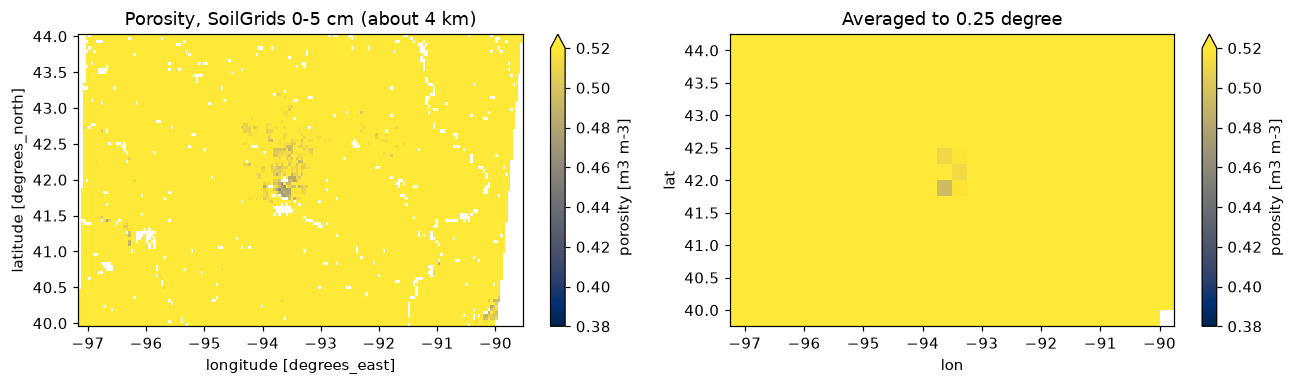

porosity 0.495 to 0.658 m3/m3


In [4]:
soil = sd.soilgrids_grid(sd.IOWA_REGION, "iowa_region", overview_level=1)  # SoilGrids over the region
phi_f = sm.porosity_from_texture(soil["sand"].isel(depth=0), soil["clay"].isel(depth=0),
                                 organic_matter=0.1724 * soil["soc"].isel(depth=0))  # porosity at about 4 km
phi = sm.regrid(phi_f.rio.write_crs(4326), ms.isel(time=0, drop=True).rio.write_crs(4326), method="average")  # average to the 0.25 degree CCI grid
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))  # fine and coarse porosity
phi_f.plot(ax=ax[0], vmin=0.38, vmax=0.52, cmap="cividis"); ax[0].set_title("Porosity, SoilGrids 0-5 cm (about 4 km)")  # fine
phi.plot(ax=ax[1], vmin=0.38, vmax=0.52, cmap="cividis"); ax[1].set_title("Averaged to 0.25 degree")  # coarse
plt.tight_layout(); plt.show()  # draw
print(f"porosity {float(phi.min()):.3f} to {float(phi.max()):.3f} m3/m3")  # range

## From degree of saturation to volumetric soil moisture

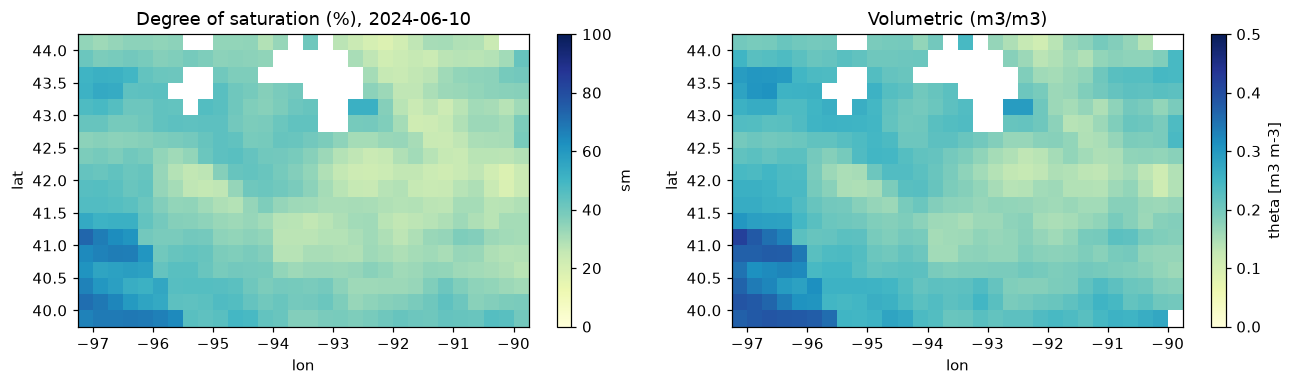

In [5]:
theta = sm.saturation_to_volumetric(ms, phi)  # theta = s phi, s from % to fraction
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))  # one day, before and after
day = "2024-06-10"  # comparison day
ms.sel(time=day).plot(ax=ax[0], cmap="YlGnBu", vmin=0, vmax=100); ax[0].set_title(f"Degree of saturation (%), {day}")  # relative
theta.sel(time=day).plot(ax=ax[1], cmap="YlGnBu", vmin=0, vmax=0.5); ax[1].set_title("Volumetric (m3/m3)")  # absolute
plt.tight_layout(); plt.show()  # draw

## Comparison with SMAP and the station

ASCAT (CCI ACTIVE) vs SMAP per 0.25 degree cell: median R 0.68


,n,bias,ubrmse,pearson_r,anomaly_r
"ASCAT, degree of saturation x porosity",1639.0,-0.027,0.083,0.690,0.650
SMAP L3E at 0.25 degree,1072.0,-0.057,0.049,0.703,0.702


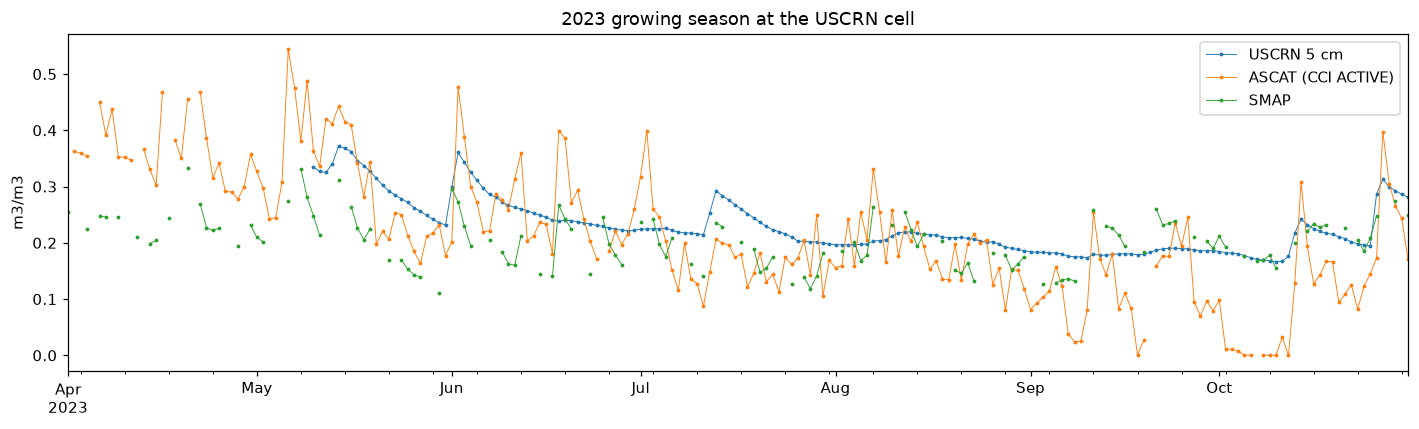

In [6]:
smap = sm.daily_cube(sm.mask_quality(sd.ease2_clip(sd.smap_l3e(), sd.IOWA_REGION).sel(time=slice("2015", "2024")))).sm  # SMAP 9 km
smap_q = sm.regrid(smap, theta.isel(time=0, drop=True).rio.write_crs(4326), method="average")  # SMAP averaged to the 0.25 degree grid
a, b = xr.align(theta, smap_q, join="inner")  # shared days
r = xr.corr(a, b, "time")  # per-cell correlation
print(f"ASCAT (CCI ACTIVE) vs SMAP per 0.25 degree cell: median R {float(r.median()):.2f}")  # agreement
ins = u.sm_5.loc["2015":"2024"]  # station 5 cm
cell = lambda da: da.sel(lat=st.lat, lon=st.lon, method="nearest").to_series()  # cell series
warm = lambda s: s[(s.index.month >= 4) & (s.index.month <= 10)]  # unfrozen months
tab = pd.DataFrame({"ASCAT, degree of saturation x porosity": sm.validation_metrics(warm(ins), warm(cell(theta)), anomalies=True),
                    "SMAP L3E at 0.25 degree": sm.validation_metrics(warm(ins), warm(cell(smap_q)), anomalies=True)}).T  # metrics
display(tab[["n", "bias", "ubrmse", "pearson_r", "anomaly_r"]].astype(float).round(3))  # table
fig, ax = plt.subplots(figsize=(13, 4))  # series at the station cell
pd.DataFrame({"USCRN 5 cm": ins, "ASCAT (CCI ACTIVE)": cell(theta), "SMAP": cell(smap_q)}).loc["2023-04":"2023-10"].plot(ax=ax, marker=".", lw=0.6, ms=3)  # 2023
ax.set_ylabel("m3/m3"); ax.set_title("2023 growing season at the USCRN cell"); plt.tight_layout(); plt.show()  # draw

The conversion with porosity gives the right order of magnitude. At the USCRN cell the converted ASCAT
record has a small bias (-0.03 m3 m-3), a correlation of 0.69 and an anomaly correlation of 0.65, close to
SMAP's (0.70 and 0.70), but a larger unbiased error (0.083 against 0.049): because the record spans the
full 0 to 100 % range by construction, its volumetric version swings wider than the station does.
Across the region the two satellite records agree with a median per-cell correlation of 0.68. For
applications that need levels, the relative record is usually rescaled to a reference (notebook 22)
rather than multiplied by porosity.

## The Soil Water Index

In [7]:
s_pt = cell(ms).dropna()  # surface degree of saturation at the station cell
deep = u[["sm_20", "sm_50", "sm_100"]].loc["2015":"2024"]  # deeper in situ layers
rows = []  # correlation per T and depth
for t in (1, 5, 10, 20, 40, 60):  # characteristic times (days)
    swi = sm.exponential_filter(s_pt, t=t)  # Soil Water Index
    for d in deep:  # each depth
        both_ = pd.concat([warm(deep[d]), swi], axis=1).dropna()  # matched days, unfrozen months
        rows.append({"T (days)": t, "depth": d, "R": both_.corr().iloc[0, 1]})  # correlation
tab = pd.DataFrame(rows).pivot(index="T (days)", columns="depth", values="R")  # table
display(tab.round(2))  # correlation of SWI with each depth

depth,sm_100,sm_20,sm_50
T (days),,,
1,0.52,0.64,0.59
5,0.63,0.71,0.68
10,0.67,0.72,0.71
20,0.69,0.68,0.71
40,0.68,0.62,0.68
60,0.68,0.59,0.67


The correlation with deeper layers rises with the characteristic time and then falls again. The 20 cm
sensor matches best with `T` of about 10 days (R 0.72), the 50 cm sensor with 10 to 20 days (0.71) and the
100 cm sensor with 20 days or more (0.69): the filter turns the noisy surface record into a smoother,
delayed series that behaves like the subsoil, and deeper layers need longer memory. Notebook 24 fits `T`
properly against root-zone data.

## Summary and exercises

- Change detection places each scatterometer measurement between the driest and wettest
  backscatter of its own record, giving a degree of saturation that needs no ancillary data.
- ESA CCI ACTIVE provides that ASCAT record openly at 0.25 degree.
- Multiplying by SoilGrids porosity converts it to volumetric water content with the right order of
  magnitude but a range wider than observed.
- At the USCRN cell the converted record correlates with the station about as well as SMAP (R 0.69
  against 0.70) but with a larger unbiased error (0.083 against 0.049 m3 m-3).
- The Soil Water Index with characteristic times of 10 to 20 days follows the 20 to 100 cm sensors
  (R about 0.7).

**Exercises**

1. Rescale the CCI ACTIVE series at the station cell to the USCRN 5 cm series with
   `sm.rescale(..., method="cdf")` and recompute the metrics. Which metrics change, and which do not?
2. Map the per-cell correlation of CCI ACTIVE and SMAP for June to August only. Where is the canopy
   effect strongest?
3. Compute the SWI for the whole cube with `sm.exponential_filter(theta, t=20)` and map its August
   2023 anomaly.